In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

In [2]:
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [4]:
import pandas as pd

url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/yelp.csv"

df = pd.read_csv(url)
df.head()

,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0
2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0


In [5]:

df = df[['text', 'stars']]


df = df[df['stars'] != 3]


df['label'] = df['stars'].apply(lambda x: 1 if x >= 4 else 0)

df.head()

,text,stars,label
0,My wife took me here on my birthday for breakf...,5,1
1,I have no idea why some people give bad review...,5,1
2,love the gyro plate. Rice is so good and I als...,4,1
3,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",5,1
4,General Manager Scott Petello is a good egg!!!...,5,1


In [6]:
df['label'].value_counts()

,count
label,
1,6863
0,1676


In [7]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\d+', '', text)

    words = text.split()

    words = [w for w in words if w not in stop_words or w in ['not','no','never']]

    words = [lemmatizer.lemmatize(w) for w in words]

    return " ".join(words)

df['clean_review'] = df['text'].apply(clean_text)

df[['text','clean_review']].head()

,text,clean_review
0,My wife took me here on my birthday for breakf...,wife took birthday breakfast excellent weather...
1,I have no idea why some people give bad review...,no idea people give bad review place go show p...
2,love the gyro plate. Rice is so good and I als...,love gyro plate rice good also dig candy selec...
3,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",rosie dakota love chaparral dog park convenien...
4,General Manager Scott Petello is a good egg!!!...,general manager scott petello good egg not go ...


In [8]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer_bow = CountVectorizer()
X_bow = vectorizer_bow.fit_transform(df['clean_review'])

print(X_bow.shape)

(8539, 29057)


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_tfidf = TfidfVectorizer()
X_tfidf = vectorizer_tfidf.fit_transform(df['clean_review'])

print(X_tfidf.shape)

(8539, 29057)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, df['label'], test_size=0.2, random_state=42
)

In [11]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

model_nb = MultinomialNB()
model_nb.fit(X_train, y_train)

y_pred_nb = model_nb.predict(X_test)

print(classification_report(y_test, y_pred_nb))

              precision    recall  f1-score   support

           0       1.00      0.00      0.01       348
           1       0.80      1.00      0.89      1360

    accuracy                           0.80      1708
   macro avg       0.90      0.50      0.45      1708
weighted avg       0.84      0.80      0.71      1708



In [12]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression()
model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.94      0.44      0.60       348
           1       0.87      0.99      0.93      1360

    accuracy                           0.88      1708
   macro avg       0.91      0.72      0.76      1708
weighted avg       0.89      0.88      0.86      1708



In [13]:


from transformers import pipeline

print("Chargement du modèle BERT... (peut prendre quelques minutes)")
bert_classifier = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    truncation=True,
    max_length=512
)

sample_size = 500
X_sample = df['clean_review'].iloc[:sample_size].tolist()
y_sample = df['label'].iloc[:sample_size].tolist()

print("Prédictions BERT en cours...")
results = bert_classifier(X_sample)

y_pred_bert = [1 if r['label'] == 'POSITIVE' else 0 for r in results]


from sklearn.metrics import classification_report, accuracy_score
print("\n=== Résultats BERT ===")
print(classification_report(y_sample, y_pred_bert))

Chargement du modèle BERT... (peut prendre quelques minutes)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Prédictions BERT en cours...

=== Résultats BERT ===
              precision    recall  f1-score   support

           0       0.43      0.97      0.60       106
           1       0.99      0.66      0.79       394

    accuracy                           0.72       500
   macro avg       0.71      0.81      0.69       500
weighted avg       0.87      0.72      0.75       500



In [14]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time


from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

X_train_bow, X_test_bow, y_train_bow, y_test_bow = train_test_split(
    X_bow, df['label'], test_size=0.2, random_state=42
)

results_dict = {}

t0 = time.time()
m1 = MultinomialNB()
m1.fit(X_train_bow, y_train_bow)
p1 = m1.predict(X_test_bow)
t1 = time.time() - t0
results_dict['BoW + NaiveBayes'] = {
    'Accuracy': accuracy_score(y_test_bow, p1),
    'Precision': precision_score(y_test_bow, p1),
    'Recall': recall_score(y_test_bow, p1),
    'F1-score': f1_score(y_test_bow, p1),
    'Temps (s)': round(t1, 3)
}


t0 = time.time()
m2 = MultinomialNB()
m2.fit(X_train, y_train)
p2 = m2.predict(X_test)
t1 = time.time() - t0
results_dict['TF-IDF + NaiveBayes'] = {
    'Accuracy': accuracy_score(y_test, p2),
    'Precision': precision_score(y_test, p2),
    'Recall': recall_score(y_test, p2),
    'F1-score': f1_score(y_test, p2),
    'Temps (s)': round(t1, 3)
}

t0 = time.time()
m3 = LogisticRegression(max_iter=1000)
m3.fit(X_train, y_train)
p3 = m3.predict(X_test)
t1 = time.time() - t0
results_dict['TF-IDF + LogisticReg'] = {
    'Accuracy': accuracy_score(y_test, p3),
    'Precision': precision_score(y_test, p3),
    'Recall': recall_score(y_test, p3),
    'F1-score': f1_score(y_test, p3),
    'Temps (s)': round(t1, 3)
}

t0 = time.time()
m4 = LinearSVC()
m4.fit(X_train, y_train)
p4 = m4.predict(X_test)
t1 = time.time() - t0
results_dict['TF-IDF + SVM'] = {
    'Accuracy': accuracy_score(y_test, p4),
    'Precision': precision_score(y_test, p4),
    'Recall': recall_score(y_test, p4),
    'F1-score': f1_score(y_test, p4),
    'Temps (s)': round(t1, 3)
}


results_dict['BERT (500 samples)'] = {
    'Accuracy': accuracy_score(y_sample, y_pred_bert),
    'Precision': precision_score(y_sample, y_pred_bert),
    'Recall': recall_score(y_sample, y_pred_bert),
    'F1-score': f1_score(y_sample, y_pred_bert),
    'Temps (s)': 'lent'
}

df_results = pd.DataFrame(results_dict).T.round(3)
print("\n=== TABLEAU COMPARATIF ===")
print(df_results.to_string())


=== TABLEAU COMPARATIF ===
                      Accuracy Precision    Recall  F1-score Temps (s)
BoW + NaiveBayes      0.879977  0.892057  0.966176  0.927639     0.031
TF-IDF + NaiveBayes   0.796838  0.796719       1.0   0.88686      0.08
TF-IDF + LogisticReg  0.880562  0.873868  0.993382    0.9298     4.105
TF-IDF + SVM          0.913934  0.919723  0.977206  0.947594     0.305
BERT (500 samples)       0.724   0.98855   0.65736  0.789634      lent


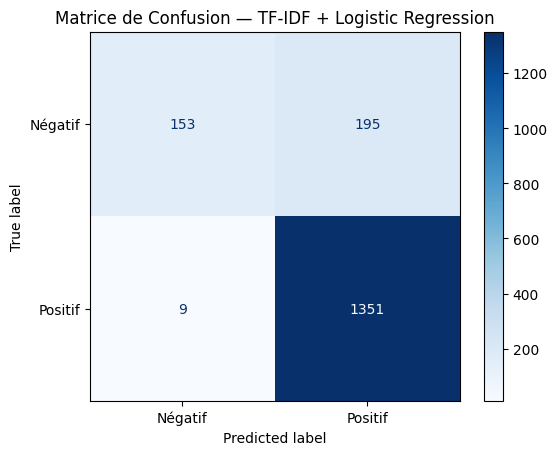

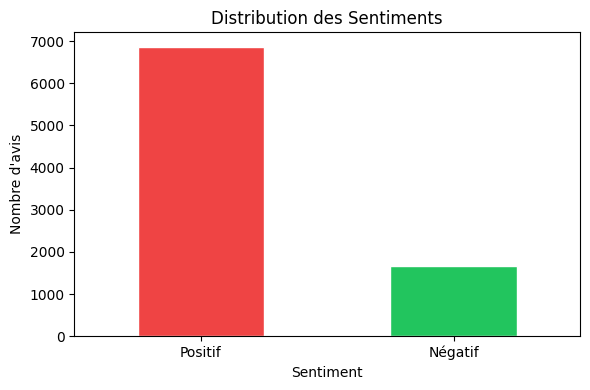

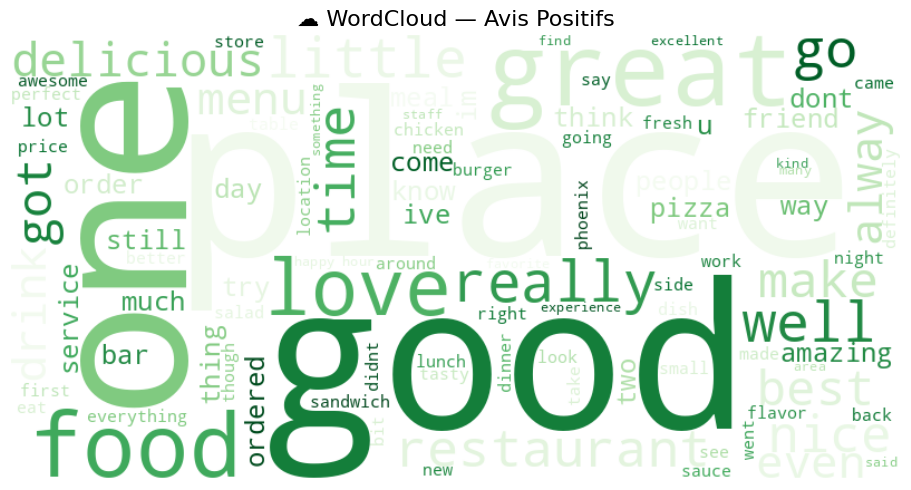

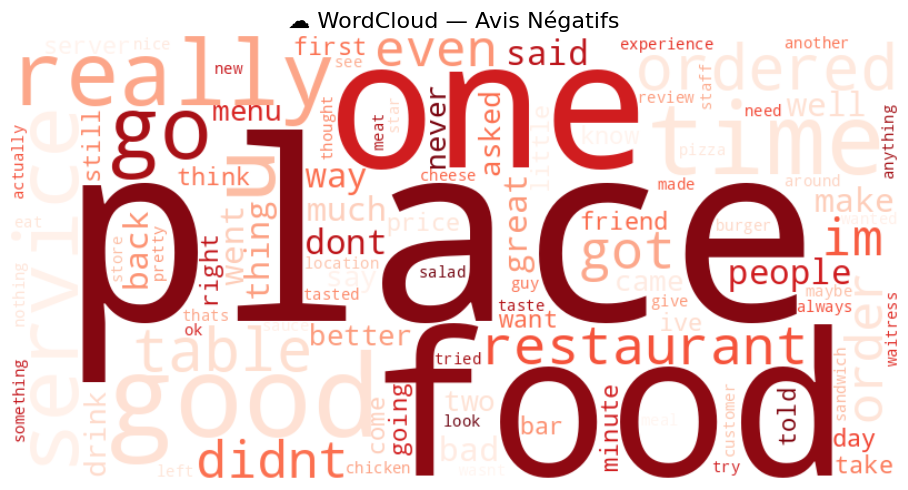

In [15]:


from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from wordcloud import WordCloud

cm = confusion_matrix(y_test, p3)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Négatif','Positif'])
disp.plot(cmap='Blues')
plt.title('Matrice de Confusion — TF-IDF + Logistic Regression')
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()


plt.figure(figsize=(6,4))
df['label'].map({0:'Négatif', 1:'Positif'}).value_counts().plot(
    kind='bar', color=['#ef4444','#22c55e'], edgecolor='white'
)
plt.title('Distribution des Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Nombre d\'avis')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('histogramme_sentiments.png', dpi=150)
plt.show()


text_pos = " ".join(df[df['label'] == 1]['clean_review'])
wc_pos = WordCloud(
    width=800, height=400,
    background_color='white',
    colormap='Greens',
    max_words=100
).generate(text_pos)

plt.figure(figsize=(10, 5))
plt.imshow(wc_pos, interpolation='bilinear')
plt.axis('off')
plt.title('☁️ WordCloud — Avis Positifs', fontsize=16)
plt.tight_layout()
plt.savefig('wordcloud_positif.png', dpi=150)
plt.show()


text_neg = " ".join(df[df['label'] == 0]['clean_review'])
wc_neg = WordCloud(
    width=800, height=400,
    background_color='white',
    colormap='Reds',
    max_words=100
).generate(text_neg)

plt.figure(figsize=(10, 5))
plt.imshow(wc_neg, interpolation='bilinear')
plt.axis('off')
plt.title('☁️ WordCloud — Avis Négatifs', fontsize=16)
plt.tight_layout()
plt.savefig('wordcloud_negatif.png', dpi=150)
plt.show()